[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/07_multi_head_attention.ipynb)

# 07 · Multi-Head Attention

*Attention, Explained · Hamza Hentabli, Ph.D. · ~30 min*

One attention head gives each word **one** place to look. But a word often needs several kinds of information at once. **Multi-head attention** runs several attention heads side by side. In this notebook we implement it, then train a tiny model and *see* different heads learn different jobs — and measure what happens when there are too few heads.

**Learning objectives.** By the end of this notebook you will be able to:

- explain why **several heads** beat one head of the same total size
- implement multi-head attention with **reshape / concat / $W_O$**
- train a one-layer model and **visualise what each head learned**
- connect toy heads to the **previous-token / positional heads** found in real models

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. Why one head is not enough

A single attention head produces **one** probability distribution per query. If a word needs to collect *several different things at once* — its previous word, its subject, the start of the sentence — one distribution has to average them together and the signals blur.

**Multi-head attention** runs $h$ attention heads **in parallel**, each with its own small $W_Q, W_K, W_V$ (dimension $d_{head} = d_{model}/h$), then concatenates their outputs and mixes them with one more matrix $W_O$:

$$\text{MultiHead}(X) = \text{Concat}(\text{head}_1, \dots, \text{head}_h)\, W_O, \qquad \text{head}_i = \text{Attention}(XW_Q^{(i)}, XW_K^{(i)}, XW_V^{(i)})$$

The total cost is about the same as one big head; what we gain is **several independent "looks"**.

## 2. Multi-head attention in NumPy: it's all reshaping

The trick used in every real implementation: compute Q, K, V for all heads with one matrix multiply, then **reshape** `(tokens, d_model)` → `(heads, tokens, d_head)`.

In [2]:
def multi_head_attention(X, WQ, WK, WV, WO, n_heads):
    T, d_model = X.shape
    d_head = d_model // n_heads
    split = lambda M: M.reshape(T, n_heads, d_head).transpose(1, 0, 2)   # (heads, T, d_head)
    Q, K, V = split(X @ WQ), split(X @ WK), split(X @ WV)
    Z, A = au.scaled_dot_product_attention(Q, K, V)                     # batched over heads
    concat = Z.transpose(1, 0, 2).reshape(T, d_model)                  # glue heads back together
    return concat @ WO, A

rng = np.random.default_rng(0)
T, d_model, n_heads = 6, 12, 3
X = rng.normal(size=(T, d_model))
WQ, WK, WV, WO = (rng.normal(scale=d_model ** -0.5, size=(d_model, d_model)) for _ in range(4))
out, A = multi_head_attention(X, WQ, WK, WV, WO, n_heads)
print(f"X {X.shape} -> {n_heads} heads of size {d_model // n_heads} -> weights {A.shape} -> output {out.shape}")
print("each head has its own attention matrix; head 0, row 0:", A[0, 0])

X (6, 12) -> 3 heads of size 4 -> weights (3, 6, 6) -> output (6, 12)
each head has its own attention matrix; head 0, row 0: [0.249 0.313 0.064 0.111 0.082 0.18 ]


## 3. Experiment: a task that needs three looks at once

Input: a random sequence of 10 tokens. For **every** position, the model must output **three** things at the same time:

1. the **previous** token,
2. the **next** token,
3. the **first** token of the sequence.

(The sequence is treated as circular, so the "previous" of position 0 is the last token.) Each answer lives at a different position, so a single attention distribution cannot fetch all three cleanly. We train the same model with 1, 2, 3 and 4 heads, keeping the total width $d_{model} = 48$ fixed, so the only difference is how the width is split into heads.

The model is deliberately minimal: token embedding + learned position vector → **one multi-head attention layer** → three linear read-outs.

In [3]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.set_num_threads(4)

VOCAB, L, D = 16, 10, 48

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.h, self.dh = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)     # W_Q, W_K, W_V for all heads in one matrix
        self.out = nn.Linear(d_model, d_model)         # W_O
    def forward(self, x):
        B, T, Dm = x.shape
        q, k, v = self.qkv(x).split(Dm, dim=-1)
        split = lambda t: t.view(B, T, self.h, self.dh).transpose(1, 2)    # (B, heads, T, d_head)
        q, k, v = split(q), split(k), split(v)
        w = (q @ k.transpose(-1, -2) / self.dh ** 0.5).softmax(-1)        # (B, heads, T, T)
        z = (w @ v).transpose(1, 2).reshape(B, T, Dm)                     # concat heads
        return self.out(z), w

class ThreeLooks(nn.Module):
    def __init__(self, n_heads):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, D)
        self.pos = nn.Parameter(torch.randn(L, D) * 0.5)
        self.attn = MultiHeadAttention(D, n_heads)
        self.readout = nn.ModuleList([nn.Linear(D, VOCAB) for _ in range(3)])
    def forward(self, x):
        z, w = self.attn(self.emb(x) + self.pos)
        return [r(z) for r in self.readout], w

TASKS = ["previous token", "next token", "first token"]
def targets(x):
    return [torch.roll(x, 1, 1), torch.roll(x, -1, 1), x[:, :1].expand_as(x)]

def train(n_heads, steps=1500):
    au.set_seed(0)
    model = ThreeLooks(n_heads)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        x = torch.randint(0, VOCAB, (128, L))
        outs, _ = model(x)
        loss = sum(F.cross_entropy(o.reshape(-1, VOCAB), y.reshape(-1)) for o, y in zip(outs, targets(x)))
        opt.zero_grad(); loss.backward(); opt.step()
    torch.manual_seed(99)
    x = torch.randint(0, VOCAB, (2000, L))
    with torch.no_grad():
        outs, _ = model(x)
    accs = [(o.argmax(-1) == y).float().mean().item() for o, y in zip(outs, targets(x))]
    return model, accs

models, accuracy = {}, {}
for h in (1, 2, 3, 4):
    t0 = time.time()
    models[h], accuracy[h] = train(h)
    print(f"{h} head(s): " + ", ".join(f"{t} {a:.3f}" for t, a in zip(TASKS, accuracy[h])) + f"   ({time.time() - t0:.0f} s)")

1 head(s): previous token 0.874, next token 0.259, first token 0.931   (7 s)


2 head(s): previous token 0.979, next token 0.999, first token 0.993   (7 s)


3 head(s): previous token 1.000, next token 1.000, first token 1.000   (8 s)


4 head(s): previous token 1.000, next token 1.000, first token 1.000   (8 s)


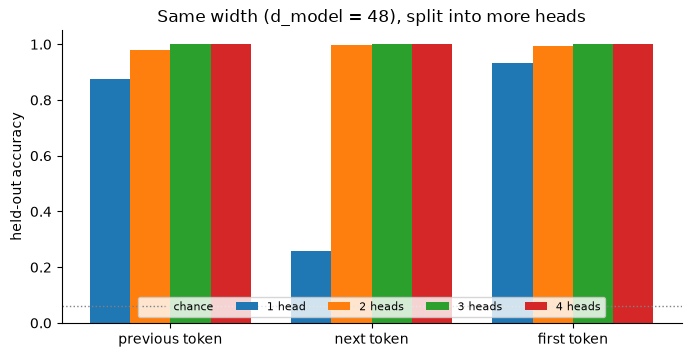

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
width = 0.2
for k, h in enumerate(accuracy):
    ax.bar(np.arange(3) + (k - 1.5) * width, accuracy[h], width, label=f"{h} head{'s' if h > 1 else ''}")
ax.axhline(1 / VOCAB, color="grey", ls=":", lw=1, label="chance")
ax.set_xticks(range(3)); ax.set_xticklabels(TASKS); ax.set_ylabel("held-out accuracy"); ax.set_ylim(0, 1.05)
ax.set_title("Same width (d_model = 48), split into more heads"); ax.legend(fontsize=8, ncol=5, loc="lower center")
plt.show()

With one head the model cannot fetch all three answers (look at the *next token* bar). Two heads already get close, and with three or more every task is solved on held-out sequences. Let's open the 3-head model and see what each head learned.

head 1: previous-token head  mean max-weight 0.96


head 2: first-token head     mean max-weight 1.00
head 3: next-token head      mean max-weight 0.92


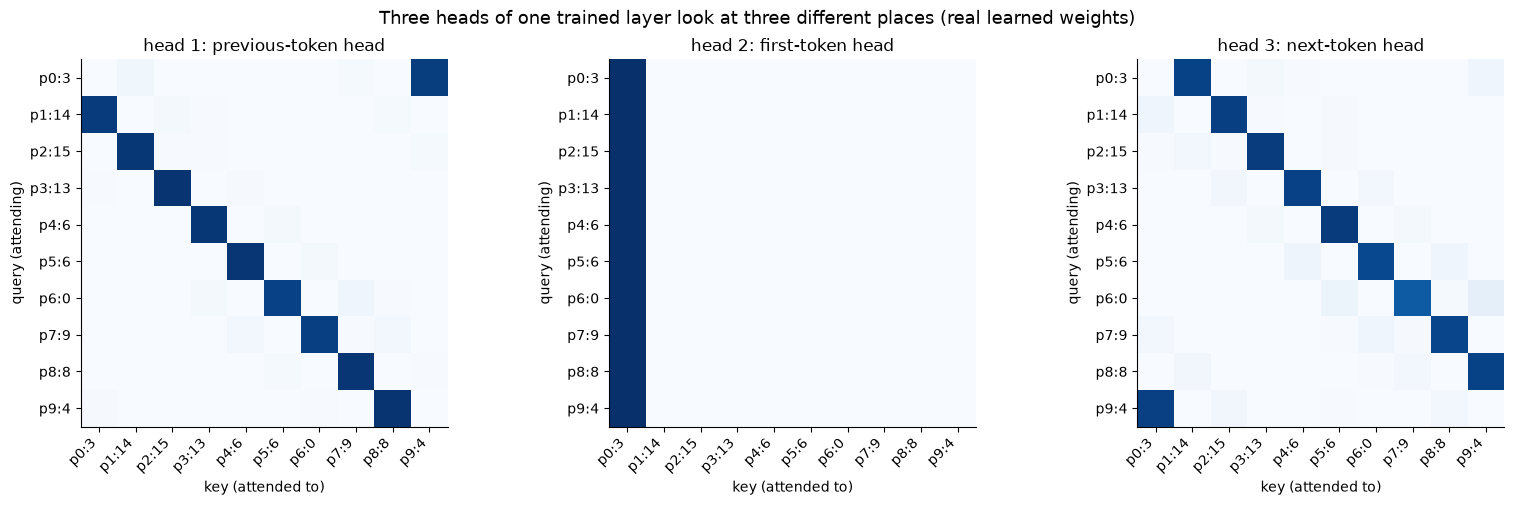

In [5]:
model3 = models[3]
torch.manual_seed(5)
x = torch.randint(0, VOCAB, (1, L))
with torch.no_grad():
    _, w = model3(x)
W3 = w[0].numpy()                         # (heads, L, L)
labels = [f"p{i}:{t}" for i, t in enumerate(x[0].tolist())]

def describe(Wh):
    tgt = Wh.argmax(-1)
    if np.all(tgt == (np.arange(L) - 1) % L): return "previous-token head"
    if np.all(tgt == (np.arange(L) + 1) % L): return "next-token head"
    if np.all(tgt == 0): return "first-token head"
    return "mixed head"

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for h in range(3):
    au.plot_attention(W3[h], labels, labels, ax=axes[h], annotate=False, vmax=1,
                      title=f"head {h + 1}: {describe(W3[h])}")
    print(f"head {h + 1}: {describe(W3[h]):20s} mean max-weight {W3[h].max(-1).mean():.2f}")
fig.suptitle("Three heads of one trained layer look at three different places (real learned weights)", fontsize=13)
plt.tight_layout()
au.save_fig(fig, "07_multihead_grid.png")
plt.show()

Each head learned a clean, different pattern: one is a **diagonal shifted down** (previous token), one is **shifted up** (next token), and one is a **single column** (everyone looks at position 0). Which head ends up doing which job depends on the random initialisation — the heads are interchangeable, the *division of labour* is what matters.

### Heads in real models

These exact patterns — *previous-token heads*, *next-token heads*, heads that park on the first token or on punctuation — are among the most commonly reported heads in trained BERT and GPT models (Clark et al., 2019; Voita et al., 2019). Others track syntax (verb → object) or coreference. Voita et al. also showed many heads can be **pruned** with little loss, while a few specialised heads do most of the work.

## Key takeaways

- **Multi-head attention** = several attention operations in parallel on smaller slices, then concatenate and mix with $W_O$.
- Implementation is mostly **reshaping** `(T, d_model) ↔ (heads, T, d_head)`.
- Heads **specialise**: here, measurably, 1 head fails a 3-lookup task that 3 heads solve perfectly.

### ✏️ Exercise 1

Print the accuracy table again but only for the *next token* task. How many heads were needed to go above 0.95?

<details>
<summary><b>Show solution</b></summary>

```python
for h, accs in accuracy.items():
    print(h, round(accs[1], 3))
```



</details>

### ✏️ Exercise 2

Show the 4 heads of the 4-head model. Do two heads end up doing the same job?

<details>
<summary><b>Show solution</b></summary>

```python
with torch.no_grad():
    _, w4 = models[4](x)
for h in range(4):
    print(h + 1, describe(w4[0, h].numpy()))
```

With more heads than jobs, some heads become redundant or split a job between them.

</details>

### ✏️ Exercise 3

Using the NumPy `multi_head_attention` function, verify that with `n_heads=1` it equals single-head attention followed by `@ WO`.

<details>
<summary><b>Show solution</b></summary>

```python
out1, _ = multi_head_attention(X, WQ, WK, WV, WO, 1)
Z1, _ = au.scaled_dot_product_attention(X @ WQ, X @ WK, X @ WV)
print(np.allclose(out1, Z1 @ WO))
```



</details>